In [36]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings("ignore")

In [37]:
price = pd.read_parquet(
    "../datasets/modeling/price_dataset_training.parquet"
)

In [38]:
price_features = price.copy()

In [39]:
print(price_features.shape)

price_features.head()

(128723, 17)


,State,Year,Month,Standard_Crop,Avg_Modal_Price,Median_Modal_Price,Price_STD,Min_Modal_Price,Max_Modal_Price,Market_Records,Unique_Markets,Avg_Temperature_C,Avg_DewPoint_C,Avg_Rainfall_mm,Avg_Wind_Speed,Avg_Surface_Pressure_hPa,Grid_Points
0,Andaman And Nicobar Islands,2003,2,Banana,1700.0,2050.0,476.130234,1000.0,2050.0,7,1,26.805517,21.673004,0.338364,4.129658,1009.62616,10.0
1,Andaman And Nicobar Islands,2003,2,Bhindi,2444.0,2800.0,501.627352,1800.0,2810.0,5,1,26.805517,21.673004,0.338364,4.129658,1009.62616,10.0
2,Andaman And Nicobar Islands,2003,2,Bitter Gourd,2102.5,2100.0,580.251382,1600.0,2610.0,4,1,26.805517,21.673004,0.338364,4.129658,1009.62616,10.0
3,Andaman And Nicobar Islands,2003,2,Bottle Gourd,1312.5,1325.0,332.603367,1000.0,1600.0,4,1,26.805517,21.673004,0.338364,4.129658,1009.62616,10.0
4,Andaman And Nicobar Islands,2003,2,Brinjal,1500.0,1400.0,513.371211,1010.0,2060.0,5,1,26.805517,21.673004,0.338364,4.129658,1009.62616,10.0


In [40]:
price_features = price_features.sort_values(
    by=["State", "Standard_Crop", "Year", "Month"]
).reset_index(drop=True)

In [41]:
price_features[
    (price_features["State"] == "Uttar Pradesh") &
    (price_features["Standard_Crop"] == "Potato")
][
    ["Year", "Month", "Avg_Modal_Price"]
].head(20)

,Year,Month,Avg_Modal_Price
118721,2002,6,486.666667
118722,2002,7,487.142857
118723,2002,8,522.142857
118724,2002,9,551.552632
118725,2002,10,602.035000
118726,2002,11,597.317972
118727,2002,12,289.146853
118728,2003,1,182.602302
118729,2003,2,192.476253
118730,2003,3,193.074074


In [42]:
price_features["Log_Price"] = np.log1p(
    price_features["Avg_Modal_Price"]
)

In [43]:
price_features[
    ["Avg_Modal_Price", "Log_Price"]
].head()

,Avg_Modal_Price,Log_Price
0,16000.000000,9.680406
1,16333.333333,9.701025
2,15700.000000,9.661480
3,4000.000000,8.294300
4,4550.000000,8.423102


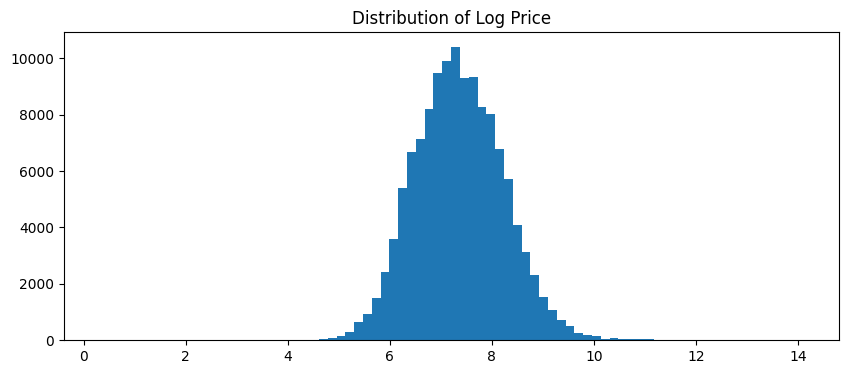

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.hist(
    price_features["Log_Price"],
    bins=80
)

plt.title("Distribution of Log Price")

plt.show()

In [45]:
price_features["Price_Lag_1"] = (
    price_features
    .groupby(["State", "Standard_Crop"])["Log_Price"]
    .shift(1)
)

In [46]:
price_features["Price_Lag_2"] = (
    price_features
    .groupby(["State", "Standard_Crop"])["Log_Price"]
    .shift(2)
)

In [47]:
price_features["Price_Lag_3"] = (
    price_features
    .groupby(["State", "Standard_Crop"])["Log_Price"]
    .shift(3)
)

In [48]:
price_features[
    (price_features["State"] == "Uttar Pradesh") &
    (price_features["Standard_Crop"] == "Potato")
][[
    "Year",
    "Month",
    "Log_Price",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3"
]].head(15)

,Year,Month,Log_Price,Price_Lag_1,Price_Lag_2,Price_Lag_3
118721,2002,6,6.189632,NaN,NaN,NaN
118722,2002,7,6.190608,6.189632,NaN,NaN
118723,2002,8,6.259855,6.190608,6.189632,NaN
118724,2002,9,6.314549,6.259855,6.190608,6.189632
118725,2002,10,6.401975,6.314549,6.259855,6.190608
118726,2002,11,6.394122,6.401975,6.314549,6.259855
118727,2002,12,5.670387,6.394122,6.401975,6.314549
118728,2003,1,5.212772,5.670387,6.394122,6.401975
118729,2003,2,5.265155,5.212772,5.670387,6.394122
118730,2003,3,5.268240,5.265155,5.212772,5.670387


In [49]:
price_features["Rolling_Mean_3"] = (
    price_features
    .groupby(["State", "Standard_Crop"])["Log_Price"]
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

In [50]:
price_features["Rolling_Mean_6"] = (
    price_features
    .groupby(["State", "Standard_Crop"])["Log_Price"]
    .transform(lambda x: x.shift(1).rolling(6).mean())
)

In [51]:
price_features["Rolling_STD_3"] = (
    price_features
    .groupby(["State", "Standard_Crop"])["Log_Price"]
    .transform(lambda x: x.shift(1).rolling(3).std())
)

In [52]:
price_features[
    (price_features["State"] == "Uttar Pradesh") &
    (price_features["Standard_Crop"] == "Potato")
][[
    "Year",
    "Month",
    "Log_Price",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Rolling_Mean_3",
    "Rolling_Mean_6",
    "Rolling_STD_3"
]].head(15)

,Year,Month,Log_Price,Price_Lag_1,Price_Lag_2,Price_Lag_3,Rolling_Mean_3,Rolling_Mean_6,Rolling_STD_3
118721,2002,6,6.189632,NaN,NaN,NaN,NaN,NaN,NaN
118722,2002,7,6.190608,6.189632,NaN,NaN,NaN,NaN,NaN
118723,2002,8,6.259855,6.190608,6.189632,NaN,NaN,NaN,NaN
118724,2002,9,6.314549,6.259855,6.190608,6.189632,6.213365,NaN,0.040264
118725,2002,10,6.401975,6.314549,6.259855,6.190608,6.255004,NaN,0.062113
118726,2002,11,6.394122,6.401975,6.314549,6.259855,6.325460,NaN,0.071686
118727,2002,12,5.670387,6.394122,6.401975,6.314549,6.370215,6.291790,0.048368
118728,2003,1,5.212772,5.670387,6.394122,6.401975,6.155495,6.205249,0.420134
118729,2003,2,5.265155,5.212772,5.670387,6.394122,5.759094,6.042277,0.595650
118730,2003,3,5.268240,5.265155,5.212772,5.670387,5.382771,5.876493,0.250456


In [53]:
price_features["Quarter"] = (
    (price_features["Month"] - 1) // 3 + 1
)

In [54]:
price_features["Month_Sin"] = np.sin(
    2 * np.pi * price_features["Month"] / 12
)

In [55]:
price_features["Month_Cos"] = np.cos(
    2 * np.pi * price_features["Month"] / 12
)

In [56]:
price_features[
    ["Month", "Quarter", "Month_Sin", "Month_Cos"]
].drop_duplicates().sort_values("Month")

,Month,Quarter,Month_Sin,Month_Cos
16,1,1,5.000000e-01,8.660254e-01
6,2,1,8.660254e-01,5.000000e-01
7,3,1,1.000000e+00,6.123234e-17
8,4,2,8.660254e-01,-5.000000e-01
9,5,2,5.000000e-01,-8.660254e-01
10,6,2,1.224647e-16,-1.000000e+00
22,7,3,-5.000000e-01,-8.660254e-01
3,8,3,-8.660254e-01,-5.000000e-01
0,9,3,-1.000000e+00,-1.836970e-16
1,10,4,-8.660254e-01,5.000000e-01


In [57]:
price_features["Previous_Change"] = (
    price_features["Price_Lag_1"] -
    price_features["Price_Lag_2"]
)

price_features["Previous_Growth"] = (
    price_features["Previous_Change"] /
    price_features["Price_Lag_2"]
)

In [67]:
price_features[
    ["Previous_Change", "Previous_Growth"]
].isnull().sum()

Previous_Change    0
Previous_Growth    0
dtype: int64

In [66]:
price_features = price_features.dropna().reset_index(drop=True)

In [59]:
price_features["Temp_Rainfall"] = (
    price_features["Avg_Temperature_C"] *
    price_features["Avg_Rainfall_mm"]
)

price_features["Temp_DewPoint"] = (
    price_features["Avg_Temperature_C"] -
    price_features["Avg_DewPoint_C"]
)

price_features["Rainfall_Wind"] = (
    price_features["Avg_Rainfall_mm"] *
    price_features["Avg_Wind_Speed"]
)

In [68]:
price_features.isnull().sum().sort_values(ascending=False)

State                       0
Year                        0
Month                       0
Standard_Crop               0
Avg_Modal_Price             0
Median_Modal_Price          0
Price_STD                   0
Min_Modal_Price             0
Max_Modal_Price             0
Market_Records              0
Unique_Markets              0
Avg_Temperature_C           0
Avg_DewPoint_C              0
Avg_Rainfall_mm             0
Avg_Wind_Speed              0
Avg_Surface_Pressure_hPa    0
Grid_Points                 0
Log_Price                   0
Price_Lag_1                 0
Price_Lag_2                 0
Price_Lag_3                 0
Rolling_Mean_3              0
Rolling_Mean_6              0
Rolling_STD_3               0
Quarter                     0
Month_Sin                   0
Month_Cos                   0
Previous_Change             0
Previous_Growth             0
Temp_Rainfall               0
Temp_DewPoint               0
Rainfall_Wind               0
dtype: int64

In [69]:
price_features = price_features.dropna().reset_index(drop=True)

In [70]:
print(price_features.shape)

price_features.isnull().sum()

(120298, 32)


State                       0
Year                        0
Month                       0
Standard_Crop               0
Avg_Modal_Price             0
Median_Modal_Price          0
Price_STD                   0
Min_Modal_Price             0
Max_Modal_Price             0
Market_Records              0
Unique_Markets              0
Avg_Temperature_C           0
Avg_DewPoint_C              0
Avg_Rainfall_mm             0
Avg_Wind_Speed              0
Avg_Surface_Pressure_hPa    0
Grid_Points                 0
Log_Price                   0
Price_Lag_1                 0
Price_Lag_2                 0
Price_Lag_3                 0
Rolling_Mean_3              0
Rolling_Mean_6              0
Rolling_STD_3               0
Quarter                     0
Month_Sin                   0
Month_Cos                   0
Previous_Change             0
Previous_Growth             0
Temp_Rainfall               0
Temp_DewPoint               0
Rainfall_Wind               0
dtype: int64

In [71]:
price_features.info()

<class 'pandas.DataFrame'>
RangeIndex: 120298 entries, 0 to 120297
Data columns (total 32 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   State                     120298 non-null  str    
 1   Year                      120298 non-null  int32  
 2   Month                     120298 non-null  int32  
 3   Standard_Crop             120298 non-null  str    
 4   Avg_Modal_Price           120298 non-null  float64
 5   Median_Modal_Price        120298 non-null  float64
 6   Price_STD                 120298 non-null  float64
 7   Min_Modal_Price           120298 non-null  float64
 8   Max_Modal_Price           120298 non-null  float64
 9   Market_Records            120298 non-null  int64  
 10  Unique_Markets            120298 non-null  int64  
 11  Avg_Temperature_C         120298 non-null  float32
 12  Avg_DewPoint_C            120298 non-null  float32
 13  Avg_Rainfall_mm           120298 non-null  float32
 14 

In [72]:
price_features.describe()

,Year,Month,Avg_Modal_Price,Median_Modal_Price,Price_STD,Min_Modal_Price,Max_Modal_Price,Market_Records,Unique_Markets,Avg_Temperature_C,...,Rolling_Mean_6,Rolling_STD_3,Quarter,Month_Sin,Month_Cos,Previous_Change,Previous_Growth,Temp_Rainfall,Temp_DewPoint,Rainfall_Wind
count,120298.000000,120298.000000,1.202980e+05,1.202980e+05,1.202980e+05,1.202980e+05,1.202980e+05,120298.000000,120298.000000,120298.000000,...,120298.000000,120298.000000,120298.000000,1.202980e+05,1.202980e+05,120298.000000,120298.000000,120298.000000,120298.000000,120298.000000
mean,2009.313812,6.557274,2.474805e+03,2.419976e+03,5.585487e+02,1.551120e+03,4.022001e+03,185.257344,13.103069,24.023346,...,7.347766,0.145536,2.517739,-7.189527e-03,-2.142515e-03,0.009077,0.002453,92.924438,7.552379,6.052771
std,3.731569,3.443535,9.459801e+03,9.181491e+03,8.196516e+03,8.203456e+03,2.613875e+04,390.416094,21.697847,7.065810,...,0.824348,0.190590,1.116298,7.054032e-01,7.087724e-01,0.307078,0.062331,123.755035,4.397248,10.653051
min,2001.000000,1.000000,3.500000e-01,3.500000e-01,0.000000e+00,2.000000e-01,3.500000e-01,1.000000,1.000000,-7.941253,...,1.267972,0.000000,1.000000,-1.000000e+00,-1.000000e+00,-8.411860,-0.933902,-43.371391,1.023682,0.000000
25%,2006.000000,4.000000,8.781739e+02,8.500000e+02,1.105501e+02,4.500000e+02,1.400000e+03,17.000000,2.000000,21.206266,...,6.756875,0.037472,2.000000,-8.660254e-01,-8.660254e-01,-0.068996,-0.009329,5.168755,4.095152,0.280263
50%,2009.000000,7.000000,1.548314e+03,1.500000e+03,2.587548e+02,9.000000e+02,2.500000e+03,54.000000,5.000000,25.613695,...,7.310147,0.085150,3.000000,-2.449294e-16,-1.836970e-16,0.006284,0.000846,30.940086,6.588765,1.426984
75%,2013.000000,10.000000,2.874615e+03,2.800000e+03,5.472023e+02,1.750000e+03,4.351000e+03,182.750000,15.000000,28.538929,...,7.909122,0.184079,4.000000,5.000000e-01,8.660254e-01,0.087451,0.011978,148.567444,9.858326,6.858562
max,2015.000000,12.000000,1.330147e+06,1.312500e+06,1.955271e+06,1.312500e+06,5.407350e+06,9075.000000,219.000000,36.356098,...,13.781380,4.831668,4.000000,1.000000e+00,1.000000e+00,6.920982,11.826774,1242.907593,24.696482,214.705673


In [65]:
price_features.to_parquet(
    "../datasets/modeling/price_features.parquet",
    index=False
)

price_features.to_csv(
    "../datasets/modeling/price_features.csv",
    index=False
)